# 03 · Learning-rate schedules (and finding a good learning rate)

**Goal:** see what each schedule in `src/schedulers.py` does, learn the **LR range test** for picking a starting LR,
and measure how schedules change training on a small problem. CPU only, about a minute.

**Why change the LR at all?** The learning rate is the size of each optimizer step. A *large* LR makes quick progress
early but keeps bouncing around the minimum at the end. A *small* LR is precise but slow (and can get stuck). A
**schedule** gives you both: start bigger, finish smaller. Many also start with a short **warmup**.

In [1]:
import sys, pathlib

# Make `import src...` work whether this notebook is opened from learn/ or from the repo root.
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("torch", torch.__version__, "| repo root:", ROOT)
import math
import torch.nn as nn
from src.schedulers import build_scheduler, simulate_schedule, warmup_cosine_factor, SCHEDULER_NAMES
from src.optim import build_optimizer
from src.losses import build_loss
print("schedules wired into train.py:", SCHEDULER_NAMES)

torch 2.15.0+cpu | repo root: D:\ali\Programming\D&D
schedules wired into train.py: ('constant', 'step', 'cosine', 'warmup_cosine', 'onecycle')


## 1. The five schedules

Below: base LR `1e-3`, 10 epochs of 50 steps each. We step the scheduler **after every batch** (smoother than once per
epoch). `onecycle` starts at `max_lr / 25`, rises to the base LR, then anneals to almost zero.

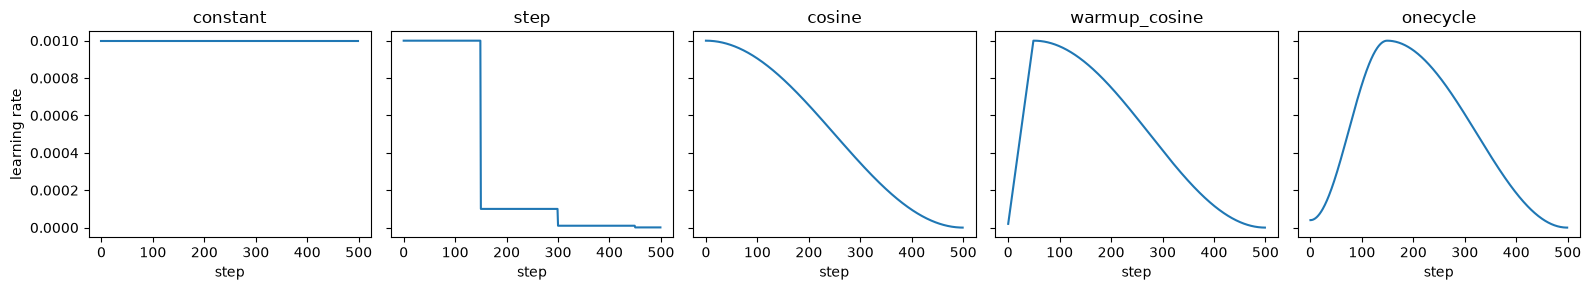

In [2]:
epochs, steps_per_epoch, base_lr = 10, 50, 1e-3
fig, axes = plt.subplots(1, len(SCHEDULER_NAMES), figsize=(16, 3), sharey=True)
for ax, name in zip(axes, SCHEDULER_NAMES):
    lrs = simulate_schedule(name, base_lr, epochs, steps_per_epoch, warmup_epochs=1.0)
    ax.plot(lrs); ax.set_title(name); ax.set_xlabel("step")
axes[0].set_ylabel("learning rate")
plt.tight_layout(); plt.show()

**What to observe.** `constant` is the baseline; `step` drops in stairs; `cosine` glides down smoothly (slowly at first,
fastest in the middle, gently at the end); `warmup_cosine` ramps up first; `onecycle` ramps up, then goes far below the start.

## 2. Warmup: why start with a *tiny* LR?

At step 0 two things are unreliable: the new random **head** produces large, meaningless gradients that could damage the
pretrained backbone, and **Adam's** statistics (`m`, `v`) are built from a handful of samples. A large first step based
on them can wreck training. Warmup ramps the LR from ~0 to its target, giving the model time to settle.

In [3]:
warmup, total = 100, 1000
for step in [0, 1, 25, 50, 99, 100, 300, 600, 900, 999]:
    print(f"step {step:>4}: LR multiplier = {warmup_cosine_factor(step, warmup, total):.3f}")

step    0: LR multiplier = 0.010
step    1: LR multiplier = 0.020
step   25: LR multiplier = 0.260
step   50: LR multiplier = 0.510
step   99: LR multiplier = 1.000
step  100: LR multiplier = 1.000
step  300: LR multiplier = 0.883
step  600: LR multiplier = 0.413
step  900: LR multiplier = 0.030
step  999: LR multiplier = 0.000


## 3. A small playground problem

We use a **noisy** 4-arm spiral (2 inputs, 4 classes) and a tiny MLP. It trains in seconds, it is nonlinear, and the noise
means the model can *not* simply memorise everything: that is what makes the learning rate matter, as on real data.
(An easy, noise-free version hits 100% accuracy with any schedule and teaches nothing. We tried.)

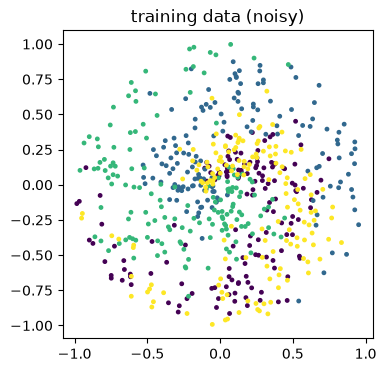

sanity run: final train loss 0.673, val loss 0.725, val acc 67.0%


In [4]:
CLASSES = 4

def make_spiral(n_per_class=150, classes=CLASSES, noise=0.7, seed=0):
    g = torch.Generator().manual_seed(seed)
    X, y = [], []
    for k in range(classes):
        r = torch.linspace(0.05, 1.0, n_per_class)
        t = torch.linspace(k * 4, (k + 1) * 4, n_per_class) + torch.randn(n_per_class, generator=g) * noise
        X.append(torch.stack([r * torch.sin(t), r * torch.cos(t)], dim=1))
        y.append(torch.full((n_per_class,), k))
    return torch.cat(X), torch.cat(y)

Xtr, ytr = make_spiral(150, seed=0)
Xva, yva = make_spiral(300, seed=1)

plt.figure(figsize=(4, 4))
plt.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, s=6, cmap="viridis"); plt.title("training data (noisy)"); plt.show()

def make_mlp(seed=0):
    torch.manual_seed(seed)   # same seed -> same initial weights -> fair comparisons between schedules
    return nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, CLASSES))

def train(opt_name, sched_name, lr, epochs=40, batch=32, wd=0.0, warmup_epochs=2, seed=0):
    model = make_mlp(seed)
    opt = build_optimizer(opt_name, model.parameters(), lr=lr, weight_decay=wd)
    steps_per_epoch = math.ceil(len(Xtr) / batch)
    sched = build_scheduler(sched_name, opt, epochs, steps_per_epoch, warmup_epochs=warmup_epochs)
    loss_fn = build_loss("cross_entropy")
    hist = {"train_loss": [], "val_loss": [], "val_acc": [], "lr": []}
    torch.manual_seed(seed + 100)   # same batch order for every schedule (given the same seed)
    for _ in range(epochs):
        model.train()
        perm, total = torch.randperm(len(Xtr)), 0.0
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
            hist["lr"].append(opt.param_groups[0]["lr"])
            sched.step()                      # <- once per BATCH
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            out = model(Xva)
            hist["val_acc"].append((out.argmax(1) == yva).float().mean().item())
            hist["val_loss"].append(loss_fn(out, yva).item())
        hist["train_loss"].append(total / len(Xtr))
    return hist

h = train("adamw", "cosine", lr=0.05)
print(f"sanity run: final train loss {h['train_loss'][-1]:.3f}, val loss {h['val_loss'][-1]:.3f}, val acc {h['val_acc'][-1]:.1%}")

## 4. Choosing the learning rate: the LR range test

Idea (Leslie Smith): start with a *tiny* LR, **increase it exponentially every batch**, and record the loss. The curve has
three phases: flat (LR too small, nothing happens), a steep **drop** (LR in the useful range), then a blow-up (LR too large).
Pick an LR in the steep-descent region, typically **about 10x below the LR where the loss is lowest**.

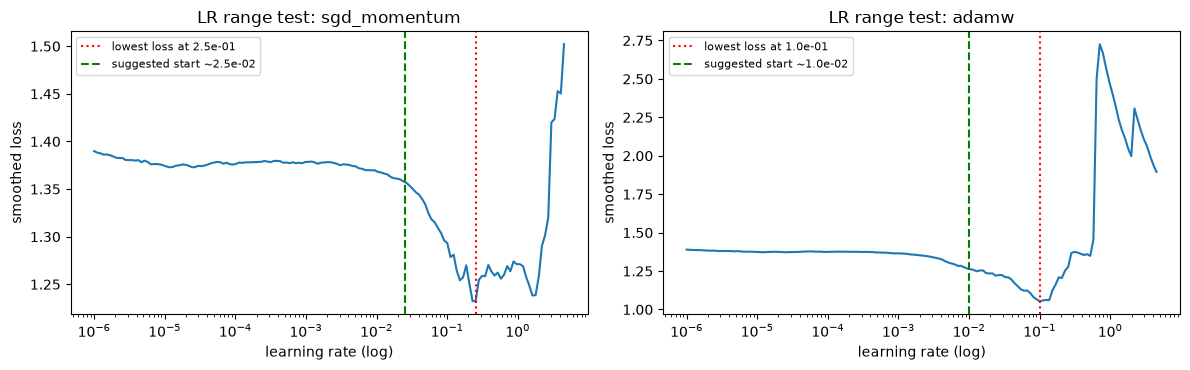

In [5]:
def lr_range_test(opt_name, min_lr=1e-6, max_lr=5.0, steps=150, batch=64):
    model = make_mlp()
    opt = build_optimizer(opt_name, model.parameters(), lr=min_lr)
    loss_fn = build_loss("cross_entropy")
    mult = (max_lr / min_lr) ** (1 / steps)          # multiply the LR by this every step
    lr, smooth, best = min_lr, None, float("inf")
    lrs, losses = [], []
    torch.manual_seed(2)
    for _ in range(steps):
        idx = torch.randint(0, len(Xtr), (batch,))
        for g in opt.param_groups:
            g["lr"] = lr
        opt.zero_grad()
        loss = loss_fn(model(Xtr[idx]), ytr[idx])
        loss.backward()
        opt.step()
        smooth = loss.item() if smooth is None else 0.9 * smooth + 0.1 * loss.item()   # smooth the noise
        lrs.append(lr); losses.append(smooth); best = min(best, smooth)
        if not math.isfinite(smooth) or smooth > 4 * best:   # diverged: stop
            break
        lr *= mult
    return lrs, losses

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, name in zip(axes, ["sgd_momentum", "adamw"]):
    lrs, losses = lr_range_test(name)
    best_lr = lrs[min(range(len(losses)), key=losses.__getitem__)]
    ax.semilogx(lrs, losses)
    ax.axvline(best_lr, color="red", ls=":", label=f"lowest loss at {best_lr:.1e}")
    ax.axvline(best_lr / 10, color="green", ls="--", label=f"suggested start ~{best_lr / 10:.1e}")
    ax.set_title(f"LR range test: {name}"); ax.set_xlabel("learning rate (log)"); ax.set_ylabel("smoothed loss"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to observe.** Both curves show the three phases: a flat start (LR too small to matter), a descent, then a blow-up.
Look at *where* each one happens: AdamW starts improving around `1e-3` and blows up around `0.7`; SGD+momentum only starts
improving around `1e-2` and survives to about `2`. So the useful window sits at a different place for each optimizer
(which is why `src/optim.py` has separate `DEFAULT_LR` values), and the suggested LR (about 10x below the lowest-loss
point) lands inside the descent region for both.

One caution: these numbers belong to *this toy network trained from scratch*. When **fine-tuning a pretrained model** the
right LRs are usually much smaller (that is why the defaults in `src/optim.py` are `5e-4` for AdamW), because we do not want
to destroy features that are already good. Run the range test again on the real task before trusting any LR.

## 5. Do schedules actually help? Same model, same data, different schedule

Everything is identical except the schedule: AdamW with a fairly high LR (`0.05`), 40 epochs, and we repeat each run with
**3 seeds** (different initial weights and batch order) so we do not mistake luck for a real effect.

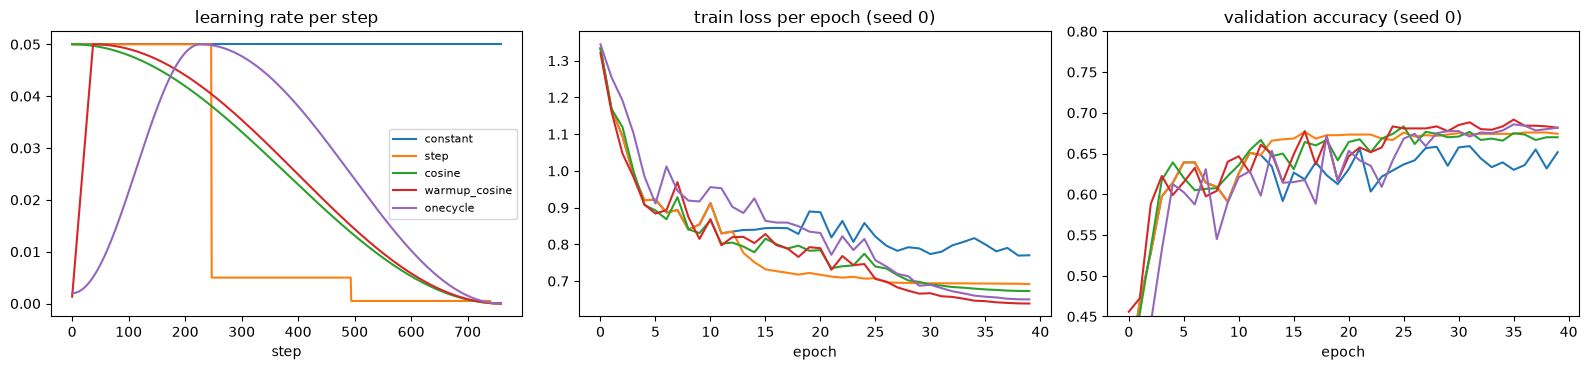

schedule           val acc (mean ± std)   val loss  train loss   jitter
constant                   65.1% ± 0.5%      0.774       0.776    0.010
step                       67.3% ± 0.8%      0.724       0.697    0.001
cosine                     67.5% ± 0.5%      0.719       0.668    0.002
warmup_cosine              67.9% ± 0.2%      0.716       0.649    0.002
onecycle                   67.7% ± 0.4%      0.714       0.653    0.002


In [6]:
import statistics as st
SEEDS = (0, 1, 2)
runs = {name: [train("adamw", name, lr=0.05, seed=s) for s in SEEDS] for name in SCHEDULER_NAMES}

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for name, hs in runs.items():           # curves of the first seed
    h = hs[0]
    ax[0].plot(h["lr"], label=name)
    ax[1].plot(h["train_loss"], label=name)
    ax[2].plot(h["val_acc"], label=name)
ax[0].set_title("learning rate per step"); ax[1].set_title("train loss per epoch (seed 0)"); ax[2].set_title("validation accuracy (seed 0)")
ax[2].set_ylim(0.45, 0.8)
for a in ax: a.set_xlabel("step" if a is ax[0] else "epoch")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

def jitter(h):  # how much does val accuracy still swing over the last 5 epochs?
    return st.pstdev(h["val_acc"][-5:])

print(f"{'schedule':<15}{'val acc (mean ± std)':>24}{'val loss':>11}{'train loss':>12}{'jitter':>9}")
for name, hs in runs.items():
    accs = [h["val_acc"][-1] for h in hs]
    print(f"{name:<15}{st.mean(accs):>17.1%} ± {st.pstdev(accs):.1%}"
          f"{st.mean(h['val_loss'][-1] for h in hs):>11.3f}{st.mean(h['train_loss'][-1] for h in hs):>12.3f}"
          f"{st.mean(jitter(h) for h in hs):>9.3f}")

**What to observe** (numbers above are the mean of 3 seeds):

* **`constant` is the worst on every column**: lowest validation accuracy, highest validation and training loss, and by far the
  highest *jitter* (its accuracy still swings from epoch to epoch at the end). Its steps never shrink, so it cannot settle
  into the minimum, however long you train.
* **All four decaying schedules** end smoother and better. The differences *between* them are small compared with the
  seed-to-seed spread (the `±`), so on a toy problem we cannot say one beats another. Do not over-read it.
* This is a small noisy problem; on a real network the lesson is the same: **decay the LR**, and spend your tuning effort
  on the *peak* LR (section 4) rather than on choosing between decaying shapes.
* `experiments/compare.py` runs this kind of comparison on the real image task.

## Summary

| Schedule | Shape | Typical use |
|---|---|---|
| `constant` | flat | baseline / quick tests |
| `step` | staircase down | classic CNN recipes (SGD) |
| `cosine` | smooth down | simple, strong default |
| `warmup_cosine` | up, then smooth down | fine-tuning, Adam/AdamW, transformers |
| `onecycle` | up, then far down | fast training in few epochs |

## Exercises

1. **Pick an LR with the range test**, then train with it, once at the suggested LR, once at 10x higher and once at 10x
   lower. Plot the three loss curves.
2. **Warmup length.** Train `warmup_cosine` with `warmup_epochs` = 0, 1, 5 and a *high* LR (0.1). When does warmup rescue
   training?
3. **Per-epoch vs per-batch.** Change the loop to call `sched.step()` once per epoch (you must then build the scheduler
   with `steps_per_epoch=1`). How do the curves differ?
4. **Write a new schedule.** Implement *linear decay to zero* as a `LambdaLR` factor function and add it to
   `src/schedulers.py` (also add its name to `SCHEDULER_NAMES`).